# Uso de IA generativa e retenção de conhecimento — análise

**MCEQ 12576 · PUC-Campinas · Projeto Final**
Equipe: Gabriel Angeli Capovilla e Henrique Della Guardia de Azevedo Martins

Este notebook reproduz todos os números do artigo, do dado bruto ao resultado. Rode as células em ordem (*Run All*).

- **Base:** Heshmati, H.; Tullis, J. G. *Using Generative AI to Answer Practice Questions Impairs Long Term Retention*. Zenodo, v1, 2026. DOI 10.5281/zenodo.23749606 (CC BY 4.0). Acesso em 16/11/2026.
- **Protocolo:** `docs/protocolo.pdf` (17/11/2026). A análise confirmatória (seções 1 a 6) segue o protocolo; a seção 7 é **exploratória**.

## 0. Configuração

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

RAIZ = Path('.')
BRUTOS = RAIZ / 'dados' / 'brutos'
LIMPOS = RAIZ / 'dados' / 'limpos'
FIGURAS = RAIZ / 'figuras'
LIMPOS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

ALFA = 0.05            # fixado no protocolo
ORDEM = ['self', 'genAI']
ROTULOS = {'self': 'Sozinho (self)', 'genAI': 'Com IA (genAI)'}
pd.set_option('display.precision', 3)

## 1. Carregar o dado bruto (Experimento 1)

O arquivo bruto **nunca é editado**. Uma linha = uma pergunta respondida por um participante.

In [2]:
bruto = pd.read_excel(BRUTOS / 'experiment1_data.xlsx')
print('Formato:', bruto.shape)
bruto.head()

Formato: (1360, 10)


,subject_id,topic,condition,item_number,question_type,initial_correct,test_correct,passage_jol,item_jol,day1_response_time_sec
0,E1P002,volcano,genAI,1,factual,1,0,9,3,23.690
1,E1P002,volcano,genAI,2,factual,1,0,9,3,26.395
2,E1P002,volcano,genAI,3,factual,0,0,9,3,24.926
3,E1P002,volcano,genAI,4,factual,1,1,9,3,23.567
4,E1P002,volcano,genAI,5,factual,1,0,9,3,21.565


### 1.1 Checagens de integridade

Conferimos o que o desenho exige: 34 participantes, 40 itens cada (4 textos × 10 perguntas), 2 textos por condição e nenhum dado faltante.

In [3]:
n_part = bruto['subject_id'].nunique()
itens_por_part = bruto.groupby('subject_id').size()
textos_por_cond = bruto.groupby(['subject_id', 'condition'])['topic'].nunique()

print('Participantes:', n_part)
print('Itens por participante:', itens_por_part.unique())
print('Textos por participante e condição:', textos_por_cond.unique())
print('Condições:', sorted(bruto['condition'].unique()))
print('Valores de test_correct:', sorted(bruto['test_correct'].unique()))
print('Dados faltantes por coluna:')
print(bruto.isna().sum())

assert n_part == 34
assert (itens_por_part == 40).all()
assert (textos_por_cond == 2).all()
assert bruto.isna().sum().sum() == 0

Participantes: 34
Itens por participante: [40]
Textos por participante e condição: [2]
Condições: ['genAI', 'self']
Valores de test_correct: [np.int64(0), np.int64(1)]
Dados faltantes por coluna:
subject_id                0
topic                     0
condition                 0
item_number               0
question_type             0
initial_correct           0
test_correct              0
passage_jol               0
item_jol                  0
day1_response_time_sec    0
dtype: int64


## 2. Limpeza e agregação

**Unidade de análise = participante** (protocolo). Para cada participante e condição, calculamos a proporção de acertos no teste final (`test_correct`) sobre os 20 itens daquela condição.

Critério de exclusão: nenhum. Todas as linhas passaram nas checagens acima, então **0 observações foram excluídas**.

In [4]:
por_part = (bruto
            .groupby(['subject_id', 'condition'])['test_correct']
            .mean()
            .unstack('condition')[ORDEM])
por_part['diferenca'] = por_part['genAI'] - por_part['self']

por_part.to_csv(LIMPOS / 'exp1_retencao_por_participante.csv')
print('Linhas excluídas: 0 | participantes analisados:', len(por_part))
por_part.head()

Linhas excluídas: 0 | participantes analisados: 34


condition,self,genAI,diferenca
subject_id,,,
E1P001,0.65,0.80,0.15
E1P002,0.95,0.60,-0.35
E1P003,0.70,0.45,-0.25
E1P004,0.80,0.65,-0.15
E1P005,0.70,0.70,0.00


## 3. Estatística descritiva

In [5]:
def resumo(serie):
    return pd.Series({'n': serie.count(), 'média': serie.mean(), 'desvio padrão': serie.std(ddof=1),
                      'mediana': serie.median(), 'mínimo': serie.min(), 'máximo': serie.max()})

descritiva = pd.DataFrame({ROTULOS['self']: resumo(por_part['self']),
                           ROTULOS['genAI']: resumo(por_part['genAI']),
                           'Diferença (genAI − self)': resumo(por_part['diferenca'])}).T
descritiva.to_csv(LIMPOS / 'exp1_tabela_descritiva.csv')
descritiva.round(3)

,n,média,desvio padrão,mediana,mínimo,máximo
Sozinho (self),34.0,0.700,0.149,0.700,0.20,0.95
Com IA (genAI),34.0,0.669,0.141,0.650,0.45,0.90
Diferença (genAI − self),34.0,-0.031,0.160,-0.025,-0.35,0.35


## 4. Gráfico principal

Cada linha cinza liga as duas condições do mesmo participante (desenho pareado). Os pontos destacados são as médias, com barras de IC 95%. O eixo Y vai de 0 a 1.

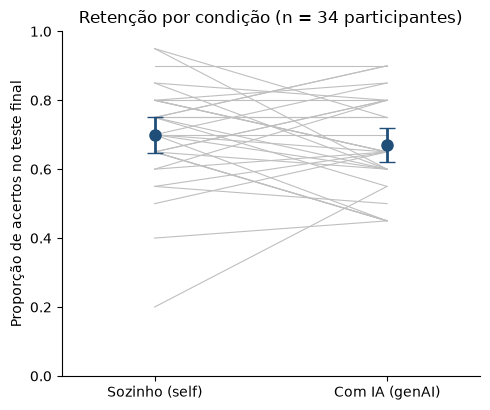

In [6]:
def ic95(x):
    x = np.asarray(x)
    m, ep = x.mean(), stats.sem(x)
    h = ep * stats.t.ppf(0.975, len(x) - 1)
    return m, m - h, m + h

fig, ax = plt.subplots(figsize=(5, 4.2))
xs = [0, 1]
for _, linha in por_part.iterrows():
    ax.plot(xs, [linha['self'], linha['genAI']], color='0.75', linewidth=0.8, zorder=1)
for x, cond in zip(xs, ORDEM):
    m, lo, hi = ic95(por_part[cond])
    ax.errorbar(x, m, yerr=[[m - lo], [hi - m]], fmt='o', color='#1f4e79', markersize=8,
                capsize=6, linewidth=2, zorder=3)
ax.set_xticks(xs, [ROTULOS[c] for c in ORDEM])
ax.set_xlim(-0.4, 1.4)
ax.set_ylim(0, 1)
ax.set_ylabel('Proporção de acertos no teste final')
ax.set_title('Retenção por condição (n = 34 participantes)')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURAS / 'fig1_retencao_pareada.png', dpi=300)
plt.show()

## 5. Pressupostos do teste t pareado

O t pareado supõe que as **diferenças** (genAI − self) são aproximadamente normais. Regra do protocolo: se Shapiro-Wilk der p < 0,05 (confirmado na inspeção gráfica), o teste principal passa a ser o **Wilcoxon pareado**.

Shapiro-Wilk nas diferenças: W = 0.967, p = 0.379


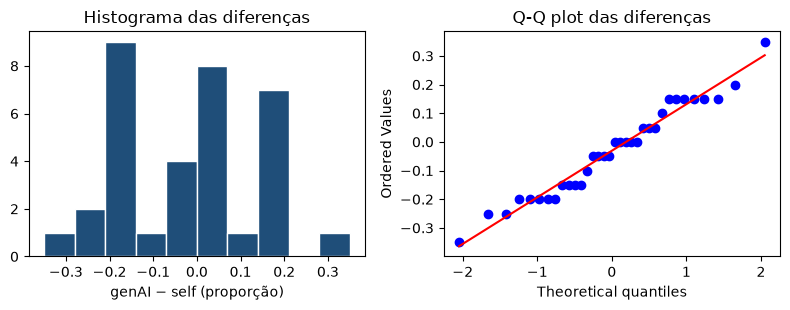

Teste principal: t pareado


In [7]:
shapiro = stats.shapiro(por_part['diferenca'])
print(f'Shapiro-Wilk nas diferenças: W = {shapiro.statistic:.3f}, p = {shapiro.pvalue:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
axes[0].hist(por_part['diferenca'], bins=10, color='#1f4e79', edgecolor='white')
axes[0].set_title('Histograma das diferenças')
axes[0].set_xlabel('genAI − self (proporção)')
stats.probplot(por_part['diferenca'], dist='norm', plot=axes[1])
axes[1].set_title('Q-Q plot das diferenças')
fig.tight_layout()
fig.savefig(FIGURAS / 'fig2_pressupostos.png', dpi=300)
plt.show()

usar_wilcoxon = shapiro.pvalue < ALFA
print('Teste principal:', 'Wilcoxon pareado' if usar_wilcoxon else 't pareado')

## 6. Teste confirmatório (H0: μ_genAI = μ_self; H1 bilateral)

Reportamos o p-valor, a decisão com α = 0,05, o tamanho de efeito d_z e o IC 95% da diferença média. Os dois testes são impressos por transparência, mas a **decisão** usa o teste definido na seção 5.

In [8]:
dif = por_part['diferenca']
n = len(dif)

# t pareado (bilateral)
t_res = stats.ttest_rel(por_part['genAI'], por_part['self'])
m_dif, lo_dif, hi_dif = ic95(dif)

# tamanho de efeito para dados pareados
d_z = dif.mean() / dif.std(ddof=1)

# Wilcoxon pareado (bilateral)
w_res = stats.wilcoxon(por_part['genAI'], por_part['self'])

print(f'Diferença média (genAI − self): {m_dif:.3f}  IC 95% [{lo_dif:.3f}; {hi_dif:.3f}]')
print(f't pareado: t({n - 1}) = {t_res.statistic:.3f}, p = {t_res.pvalue:.4f}')
print(f'Wilcoxon pareado: W = {w_res.statistic:.1f}, p = {w_res.pvalue:.4f}')
print(f'd de Cohen (d_z) = {d_z:.3f}')

p_decisao = w_res.pvalue if usar_wilcoxon else t_res.pvalue
teste = 'Wilcoxon pareado' if usar_wilcoxon else 't pareado'
decisao = 'rejeita H0' if p_decisao < ALFA else 'não rejeita H0'
print(f'\nDecisão ({teste}, α = {ALFA}): p = {p_decisao:.4f} → {decisao}')

resultado = pd.Series({'n_pares': n, 'media_self': por_part['self'].mean(), 'media_genAI': por_part['genAI'].mean(),
                       'diferenca_media': m_dif, 'ic95_inf': lo_dif, 'ic95_sup': hi_dif,
                       't': t_res.statistic, 'gl': n - 1, 'p_t': t_res.pvalue,
                       'W_wilcoxon': w_res.statistic, 'p_wilcoxon': w_res.pvalue,
                       'd_z': d_z, 'shapiro_p': shapiro.pvalue, 'teste_decisao': teste, 'decisao': decisao})
resultado.to_csv(LIMPOS / 'exp1_resultado_confirmatorio.csv', header=['valor'])

Diferença média (genAI − self): -0.031  IC 95% [-0.087; 0.025]
t pareado: t(33) = -1.129, p = 0.2672
Wilcoxon pareado: W = 161.5, p = 0.2235
d de Cohen (d_z) = -0.194

Decisão (t pareado, α = 0.05): p = 0.2672 → não rejeita H0


**Como interpretar d_z:** valores perto de 0,2 costumam ser lidos como efeito pequeno, 0,5 médio e 0,8 grande. Mas a relevância prática deve ser discutida em pontos percentuais de acerto (a diferença média e seu IC), não só pelo rótulo.

> Escrevam a interpretação no artigo **depois** de ver estes números, sem trocar teste, α ou VD.

## 7. Análises exploratórias (fora do protocolo confirmatório)

Esta seção **não testa hipóteses**. Ela só descreve padrões para discussão e próximos passos, e no artigo deve aparecer numa subseção chamada **“Análises exploratórias”**.

### 7.1 Experimento 1 por tipo de pergunta (moderadora candidata)

In [9]:
por_tipo = (bruto.groupby(['subject_id', 'question_type', 'condition'])['test_correct'].mean()
            .unstack('condition')[ORDEM])
por_tipo.groupby('question_type').agg(['mean', 'std']).round(3)

condition       self         genAI       
                mean    std   mean    std
question_type                            
factual        0.741  0.179  0.703  0.153
inference      0.659  0.196  0.635  0.195

### 7.2 Experimento 2 (4 condições, descritiva)

No Experimento 2, cada participante passa pelas 4 condições: com IA ou sozinho × resposta simples ou elaborada. Mostramos só médias e desvios.

In [10]:
bruto2 = pd.read_excel(BRUTOS / 'experiment2_data.xlsx')
print('Formato:', bruto2.shape, '| participantes:', bruto2['subject_id'].nunique())
por_part2 = bruto2.groupby(['subject_id', 'condition'])['test_correct'].mean().unstack('condition')
por_part2.to_csv(LIMPOS / 'exp2_retencao_por_participante.csv')
por_part2.agg(['count', 'mean', 'std']).T.round(3)

Formato: (1800, 10) | participantes: 45


,count,mean,std
condition,,,
genAI_elaborated,45.0,0.540,0.195
genAI_simple,45.0,0.551,0.204
self_elaborated,45.0,0.624,0.173
self_simple,45.0,0.587,0.171


---
### Versões usadas

In [11]:
import sys, scipy, matplotlib
print('Python', sys.version.split()[0])
print('pandas', pd.__version__, '| numpy', np.__version__, '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)

Python 3.13.5
pandas 3.1.1 | numpy 2.5.5 | scipy 1.18.1 | matplotlib 3.11.2
